In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime, timedelta

In [2]:
df = pd.read_csv("./Dataframes/merged_data.csv", encoding="utf-8", parse_dates=["timestamp"], index_col = 'timestamp')

In [3]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]
print(summary)

                         total  nan_count  nan_ratio
source_file                                         
2026-01-10-13-32-12.fit    971        971        1.0
2026-01-10-13-59-21.fit   5375       5375        1.0
2026-01-10-17-37-48.fit   1274       1274        1.0
2026-01-11-11-16-39.fit   1314       1314        1.0
2026-01-11-12-00-28.fit   1848       1848        1.0
...                        ...        ...        ...
2026-08-01-09-59-59.fit   3508       3508        1.0
2026-08-02-15-56-41.fit    771          0        0.0
2026-08-02-16-12-13.fit   3023          0        0.0
2026-08-04-16-59-17.fit    620          0        0.0
2026-08-04-17-09-50.fit   2483          0        0.0

[164 rows x 3 columns]


In [4]:
rides_with_some_missing_values = summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]
print(rides_with_some_missing_values)

                         total  nan_count  nan_ratio
source_file                                         
2026-01-31-13-35-38.fit   6118         62   0.010134
2026-02-15-14-57-18.fit   4996          8   0.001601
2026-02-19-14-18-09.fit   8257         28   0.003391
2026-02-20-14-16-55.fit   8146        102   0.012521
2026-02-26-20-51-14.fit   3310        597   0.180363
2026-05-17-20-02-35.fit   4433         39   0.008798
2026-06-03-15-30-13.fit   7005          7   0.000999
2026-06-17-15-49-01.fit   6080        378   0.062171
2026-07-11-14-54-53.fit   7226         11   0.001522


In [5]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-15-14-57-18.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
print(ride_with_missing_values)

                           heart_rate  power
timestamp                                   
2026-02-15 14:53:02+00:00         NaN      0
2026-02-15 14:53:03+00:00         NaN      0
2026-02-15 14:53:04+00:00         NaN      0
2026-02-15 14:53:05+00:00         NaN      0
2026-02-15 14:53:06+00:00         NaN      0
2026-02-15 14:53:07+00:00         NaN      0
2026-02-15 14:53:08+00:00         NaN      0
2026-02-15 14:53:09+00:00         NaN      0


Das ist ein Zeitintervall ohne Unterbrechung. Schauen wir es uns mit den Werten davor und danach an.

In [6]:
def plot_power_and_heart_rate(
    df: pd.DataFrame,
    start_time: datetime,
    end_time: datetime
) -> None:
    """Plot power and heart rate for a given time range using dual y-axes.

    Args:
        df: DataFrame containing 'power' and 'heart_rate' columns with datetime index.
        start_time: Start datetime of the range (inclusive).
        end_time: End datetime of the range (inclusive).
    """
    # Filter data based on datetime range
    mask = (df.index >= start_time - timedelta(seconds=30)) & (df.index <= end_time + timedelta(seconds=30))
    subset = df.loc[mask]

    # Create figure with dual y-axes
    fig = go.Figure()

    # Add power trace (left y-axis)
    fig.add_trace(go.Scatter(
        x=subset.index,
        y=subset["power"],
        name="Power",
        mode="lines+markers",
        yaxis="y1"
    ))

    # Add heart rate trace (right y-axis)
    fig.add_trace(go.Scatter(
        x=subset.index,
        y=subset["heart_rate"],
        name="Heart Rate",
        mode="lines+markers",
        yaxis="y2"
    ))

    # Configure layout with dual axes
    fig.update_layout(
        title="Power and Heart Rate Over Time",
        xaxis_title="Time",
        yaxis=dict(title="Power (W)", side="left"),
        yaxis2=dict(title="Heart Rate (bpm)", side="right", overlaying="y"),
        legend=dict(x=0.01, y=1.1, orientation="h")
    )

    fig.show()

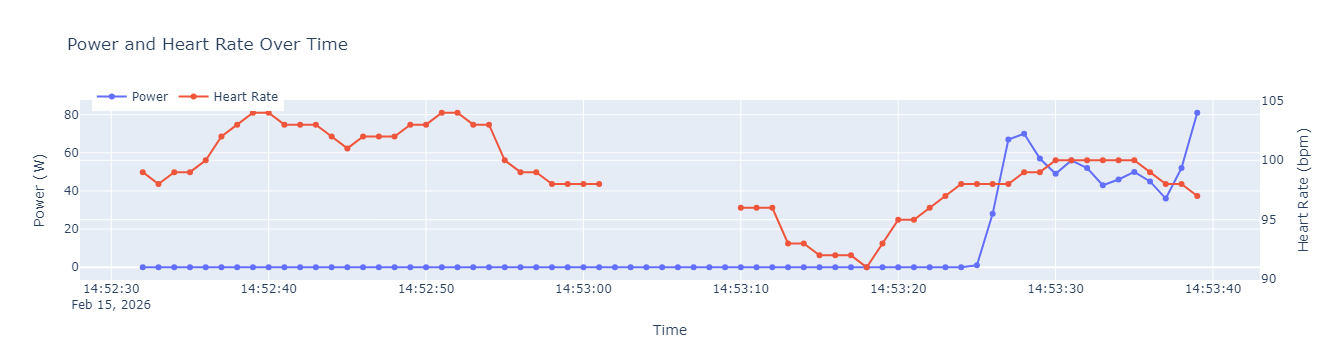

In [7]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [8]:
def interpolate_range(df: pd.DataFrame, start_time: datetime, end_time: datetime) -> pd.DataFrame:
    """Linearly interpolate NaN values in a column between two indices (inclusive) and round to int.

    Args:
        df: DataFrame containing the column to interpolate.
        column: Name of the column to interpolate.
        start_time: Start datetime of the range (inclusive).
        end_time: End datetime of the range (inclusive).

    Returns:
        The modified DataFrame (interpolation applied in place).
    """
    mask = (df.index >= start_time - timedelta(seconds=1)) & (df.index <= end_time + timedelta(seconds=1))
    df.loc[mask, 'heart_rate'] = df.loc[mask, 'heart_rate'].interpolate(method="linear").round()
    return df

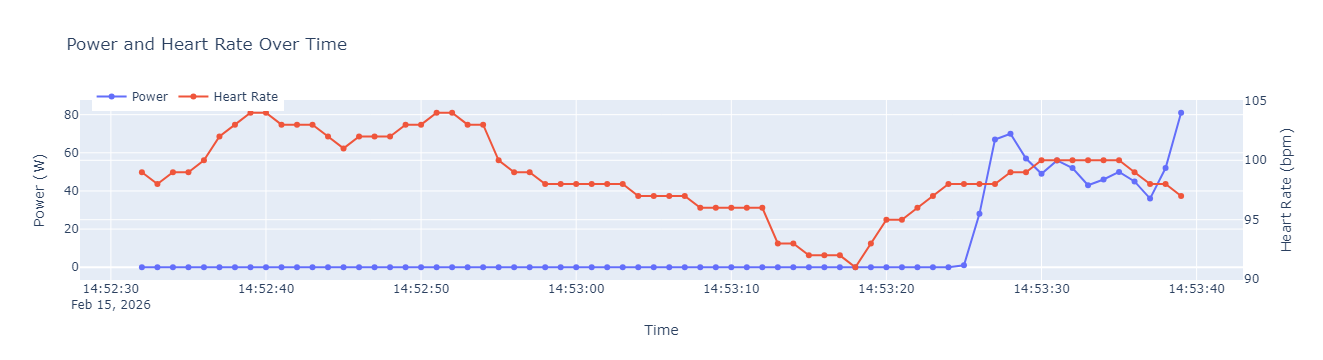

In [9]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-06-03-15-30-13.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
print(ride_with_missing_values)

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
df[df.index >= "2026-06-03 14:57:36+00:00"].head()

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-07-11-14-54-53.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
print(ride_with_missing_values)

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
plot_power_and_heart_rate(df, 458900, 458999)

Hier kann ich in den Daten keine Erklärung für den Herzfrequenz-Spike nach den fehlenden Werten entdecken. Es könnte sein, dass irgendetwas passiert ist, was die Daten nicht abbilden (z.B. ich bin schnell abgestiegen und habe einen Energieriegel geholt). Ich würde die Daten daher trotzdem linear annähern.

In [ ]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-19-14-18-09.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-05-17-20-02-35.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-01-31-13-35-38.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]

summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-20-14-16-55.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
def plot_missing_heatmap(
    df: pd.DataFrame,
    start_time: pd.Timestamp | None = None,
    end_time: pd.Timestamp | None = None,
) -> go.Figure:
    """Plot a heatmap showing where heart_rate values are missing.

    Args:
        df: DataFrame with a DatetimeIndex and a 'heart_rate' column.
        start_time: Optional start of the time range to display.
        end_time: Optional end of the time range to display.

    Returns:
        A Plotly figure showing missing vs. present values over time.
    """
    subset = df.loc[start_time:end_time]

    missing_flags = subset[["heart_rate"]].isna().astype(int).T

    fig = px.imshow(
        missing_flags,
        x=subset.index,
        y=["heart_rate"],
        color_continuous_scale=["seagreen", "crimson"],
        labels={"x": "Zeit", "color": "Fehlt"},
        title="Fehlende Werte in 'heart_rate'",
    )

    fig.update_layout(height=250)

    return fig

In [ ]:
def get_missing_intervals(
    df: pd.DataFrame,
    start_time: pd.Timestamp | None = None,
    end_time: pd.Timestamp | None = None,
) -> pd.DataFrame:
    """Extract intervals of consecutive missing heart_rate values.

    Args:
        df: DataFrame with a DatetimeIndex and a 'heart_rate' column.
        start_time: Optional start of the time range to consider.
        end_time: Optional end of the time range to consider.

    Returns:
        A DataFrame with columns 'start', 'end', and 'count' for each gap.
    """
    subset = df.loc[start_time:end_time]

    is_missing = subset["heart_rate"].isna()
    group_ids = is_missing.ne(is_missing.shift()).cumsum()

    gaps = (
        subset[is_missing]
        .groupby(group_ids[is_missing])
        .agg(
            start=("heart_rate", lambda x: x.index.min()),
            end=("heart_rate", lambda x: x.index.max()),
            count=("heart_rate", "size"),
        )
        .reset_index(drop=True)
    )

    return gaps

In [ ]:
plot_missing_heatmap(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
missing_intervals = get_missing_intervals(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
print(missing_intervals)

In [ ]:
plot_power_and_heart_rate(df, missing_intervals.start[0], missing_intervals.end[0])

In [ ]:
df = interpolate_range(df, missing_intervals.start[0], missing_intervals.end[0])
plot_power_and_heart_rate(df, missing_intervals.start[0], missing_intervals.end[0])

Nun das zweite Intervall:

In [ ]:
plot_power_and_heart_rate(df, missing_intervals.start[1], missing_intervals.end[1])

In [ ]:
df = interpolate_range(df, missing_intervals.start[1], missing_intervals.end[1])
plot_power_and_heart_rate(df, missing_intervals.start[1], missing_intervals.end[1])

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-06-17-15-49-01.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
missing_intervals = get_missing_intervals(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [ ]:
interpolate_range(df, missing_intervals.start[0], missing_intervals.end[1])
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

So, auf zur letzten Fahrt:

In [ ]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-26-20-51-14.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

In [ ]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

Bei allen bisherigen Fahrten war die getretene Leistung 0 oder gering. Mögliche Erklärung ist häufig, dass ich im Bad war und der Herzfrequenzmesser die Verbindung verloren hat. Hier hat eindeutig der Herzfrequenzmesser nicht funktioniert. In der ersten sehr großen Lücke gab es viele unterschiedliche Leistungen. In der zweiten gab es einen Leistungsspike. Daher will ich hier nicht annähern. Die dritte Lücke ist ein Jump von 50 bpm, ohne dass die Leistung widerspiegelt, warum das so sein könnte. Daher lasse ich auch hier die Werte NaN.
Schauen wir nochmal auf alle Fahrten mit teilweise fehlenden Werten:

In [ ]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]

summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]